In [35]:
from tqdm import tqdm
from req_functions_from_ApproxSP import *
from generate_profiles import *
from mallows import *
import json
from impartial import *
import pandas as pd


**Mallows**

In [79]:
data_mallows_gain = []
data_test = []

n=30
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            m_pref = [generate_ic_votes(n)[0]]*n
            w_pref = [generate_ic_votes(n)[0]]*n
            mpref= mallows_votes(m_pref, phi1)
            wpref= mallows_votes(w_pref, phi2)
            #mpref_clean = [[int(x) for x in row] for row in mpref] #these two are for saving purposes
            #wpref_clean = [[int(x) for x in row] for row in wpref]
            #mpref=m_pref[0]
            #wpref=w_pref[1]
            preferences = [mpref, wpref]
            #manipulators = []
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                #manipulators.append(manipulator)
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_test.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 6/6 [07:06<00:00, 71.01s/it]


n=50: 100%|██████████| 1/1 [00:08<00:00,  8.90s/it]


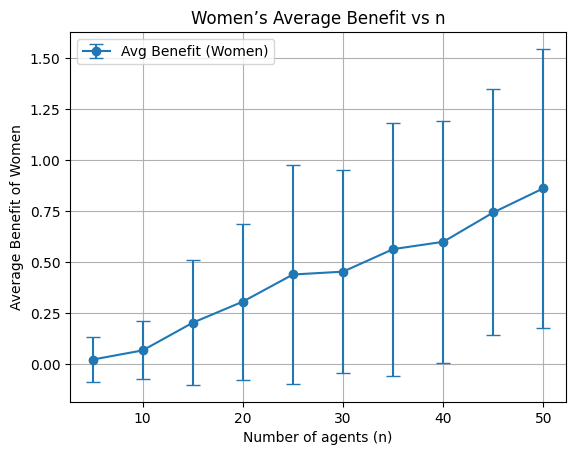

In [ ]:
#Code for varying n



import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

data_mallows_gain = []

phi_list = [1.0]
n_list = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

# store aggregated statistics
results_summary = []

for n in n_list:
    for phi1 in tqdm(phi_list, desc=f"n={n}"):
        for phi2 in tqdm(phi_list, leave=False):
            
            sample_avgs = []  # store avg benefit_women per sample

            for samples in range(100):
                # generate Mallows preferences
                m_pref = [generate_ic_votes(n)[0]] * n
                w_pref = [generate_ic_votes(n)[0]] * n
                mpref = mallows_votes(m_pref, phi1)
                wpref = mallows_votes(w_pref, phi2)

                benefit_women = []

                for manipulator in range(1, n+1):
                    # original matching
                    matching = gale_shapley(mpref, wpref)
                    result = self_manipulation(mpref, wpref, manipulator)
                    matching2 = result[0]

                    # find partners before and after manipulation
                    partner1, partner2 = None, None
                    for i in range(n):
                        if matching[i] == manipulator:
                            partner1 = i+1
                        if matching2[i] == manipulator:
                            partner2 = i+1

                    # rank positions in woman's preference
                    w_pref_m = wpref[manipulator-1]
                    rk1 = w_pref_m.index(partner1)
                    rk2 = w_pref_m.index(partner2)

                    # benefit = improvement in rank (positive = better for woman)
                    benefit = rk1 - rk2
                    benefit_women.append(benefit)

                # average benefit for this sample
                avg_benefit_women = np.mean(benefit_women)
                sample_avgs.append(avg_benefit_women)

                data_mallows_gain.append([
                    phi1, phi2, n, samples,
                    avg_benefit_women, benefit_women
                ])

            # aggregate across 100 samples
            mean_benefit = np.mean(sample_avgs)
            std_benefit = np.std(sample_avgs)

            results_summary.append([phi1, phi2, n, mean_benefit, std_benefit])

# ---- Convert results into numpy arrays for plotting ----
results_summary = np.array(results_summary, dtype=object)

# Extract plotting data
n_vals = results_summary[:, 2].astype(int)
means = results_summary[:, 3].astype(float)
stds = results_summary[:, 4].astype(float)

# ---- Plot ----
plt.errorbar(n_vals, means, yerr=stds, fmt='o-', capsize=5, label="Avg Benefit (Women)")
plt.xlabel("Number of agents (n)")
plt.ylabel("Average Benefit of Women")
plt.title("Women’s Average Benefit vs n")
plt.legend()
plt.grid(True)
plt.show()


In [78]:
print(mean_benefit)

0.8632


In [74]:
df2 = pd.DataFrame(data_mallows_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preferences", "original matchings", "manipulated matchings", "benefit"])
df2.to_csv('mallows_gain_test2.csv', index=False)

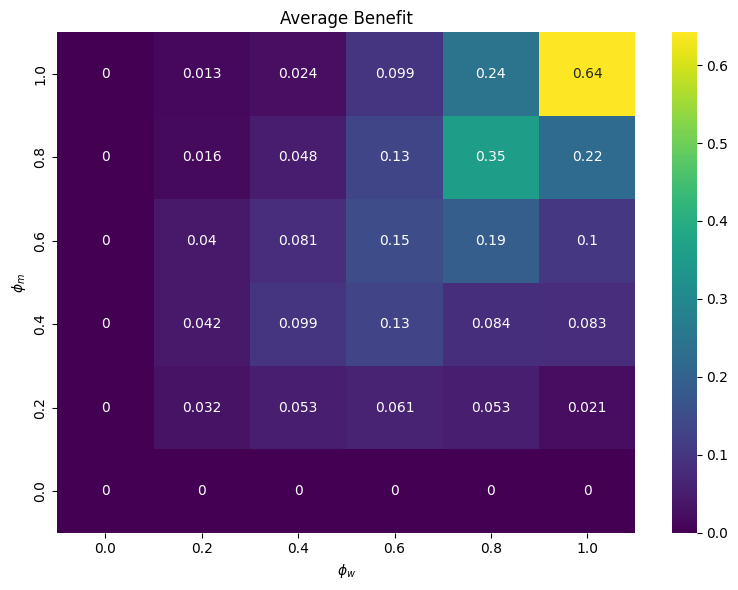

In [80]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

phi_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
phi_indices = {phi: i for i, phi in enumerate(phi_list)}

# Initialize an empty matrix to store benefit sums and counts
benefit_sums = np.zeros((len(phi_list), len(phi_list)))
benefit_counts = np.zeros((len(phi_list), len(phi_list)))

# Populate the sums and counts
for entry in data_test:
    phi_m, phi_w = entry[0], entry[1]
    benefit_list = entry[7]

    i = phi_indices[phi_m]
    j = phi_indices[phi_w]

    benefit_sums[i, j] += sum(benefit_list)
    benefit_counts[i, j] += len(benefit_list)

# Compute average benefit
average_benefits = benefit_sums / benefit_counts

# Create a DataFrame for better visualization with seaborn
df = pd.DataFrame(average_benefits, index=phi_list, columns=phi_list)

plt.figure(figsize=(8, 6))
sns.heatmap(df, annot=True, cmap='viridis', xticklabels=phi_list, yticklabels=phi_list)
plt.title("Average Benefit")
plt.xlabel(r'$\phi_w$')
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



**Mallows MD**

In [43]:
data_mallows_MD_gain = []

n=5
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref = generate_mallows_asymmetric_votes(n, phi1, phi2)
            mpref = pref[0]
            wpref = pref[1]
            #mpref_clean = [[int(x) for x in row] for row in mpref] #these two are for saving purposes
            #wpref_clean = [[int(x) for x in row] for row in wpref]
            #mpref=m_pref[0]
            #wpref=w_pref[1]
            preferences = [mpref, wpref]
            #manipulators = []
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                #manipulators.append(manipulator)
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_MD_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 6/6 [00:00<00:00,  8.76it/s]


In [45]:
df3 = pd.DataFrame(data_mallows_MD_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preference", "original matchings", "manipulated matchings", "benefit"])
df3.to_csv('mallows_MD_gain.csv', index=False)

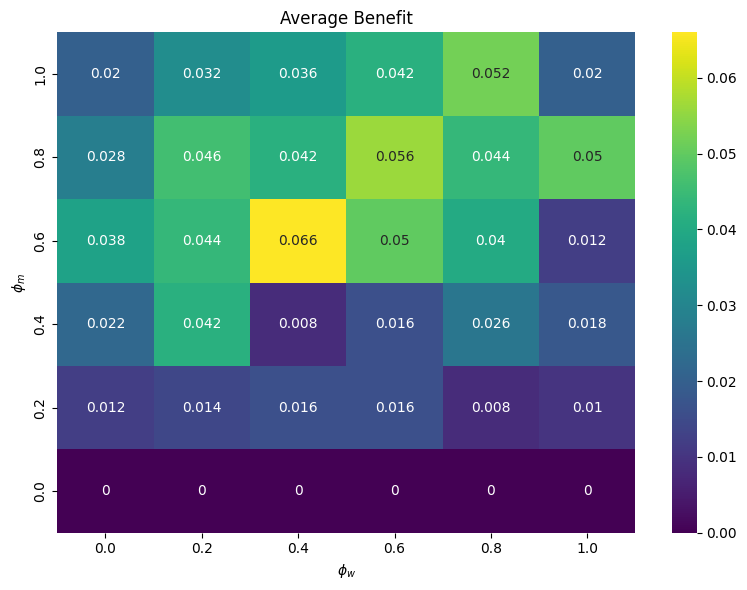

In [46]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

phi_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
phi_indices = {phi: i for i, phi in enumerate(phi_list)}

# Initialize an empty matrix to store benefit sums and counts
benefit_sums = np.zeros((len(phi_list), len(phi_list)))
benefit_counts = np.zeros((len(phi_list), len(phi_list)))

# Populate the sums and counts
for entry in data_mallows_MD_gain:
    phi_m, phi_w = entry[0], entry[1]
    benefit_list = entry[7]

    i = phi_indices[phi_m]
    j = phi_indices[phi_w]

    benefit_sums[i, j] += sum(benefit_list)
    benefit_counts[i, j] += len(benefit_list)

# Compute average benefit
average_benefits = benefit_sums / benefit_counts

# Create a DataFrame for better visualization with seaborn
df = pd.DataFrame(average_benefits, index=phi_list, columns=phi_list)

plt.figure(figsize=(8, 6))
sns.heatmap(df, annot=True, cmap='viridis', xticklabels=phi_list, yticklabels=phi_list)
plt.title("Average Benefit")
plt.xlabel(r'$\phi_w$')
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()




In [7]:
from euclidean import *

**Mallows Euclidean**

In [47]:
data_mallows_euclidean_gain = []

n=5
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref = generate_mallows_euclidean_votes(n, phi1, phi2)
            mpref = pref[0]
            wpref = pref[1]
            #mpref_clean = [[int(x) for x in row] for row in mpref] #these two are for saving purposes
            #wpref_clean = [[int(x) for x in row] for row in wpref]
            #mpref=m_pref[0]
            #wpref=w_pref[1]
            preferences = [mpref, wpref]
            #manipulators = []
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                #manipulators.append(manipulator)
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_euclidean_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 6/6 [00:01<00:00,  5.41it/s]


In [48]:
df4 = pd.DataFrame(data_mallows_euclidean_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df4.to_csv('mallows_euclidean_gain.csv', index=False)

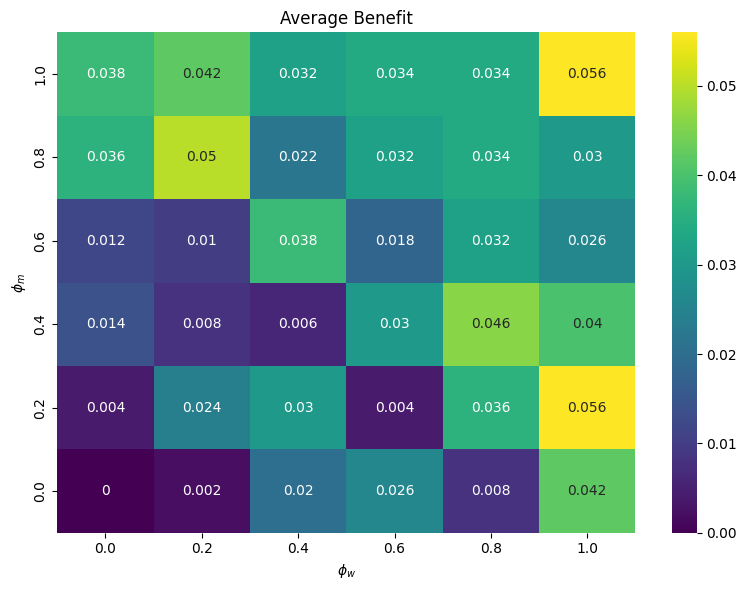

In [49]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

phi_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
phi_indices = {phi: i for i, phi in enumerate(phi_list)}

# Initialize an empty matrix to store benefit sums and counts
benefit_sums = np.zeros((len(phi_list), len(phi_list)))
benefit_counts = np.zeros((len(phi_list), len(phi_list)))

# Populate the sums and counts
for entry in data_mallows_euclidean_gain:
    phi_m, phi_w = entry[0], entry[1]
    benefit_list = entry[7]

    i = phi_indices[phi_m]
    j = phi_indices[phi_w]

    benefit_sums[i, j] += sum(benefit_list)
    benefit_counts[i, j] += len(benefit_list)

# Compute average benefit
average_benefits = benefit_sums / benefit_counts

# Create a DataFrame for better visualization with seaborn
df = pd.DataFrame(average_benefits, index=phi_list, columns=phi_list)

plt.figure(figsize=(8, 6))
sns.heatmap(df, annot=True, cmap='viridis', xticklabels=phi_list, yticklabels=phi_list)
plt.title("Average Benefit")
plt.xlabel(r'$\phi_w$')
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()




**Reverse Euclidean**

In [60]:
data_reverse_euclidean_gain = []

n=5
p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]

for d in tqdm(d_list):
    number_phi = []
    for p in tqdm(p_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref=generate_reverse_euclidean_votes(n, d, 'uniform', 0.5, p)
            mpref=pref[0]
            wpref=pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_reverse_euclidean_gain.append([d, p, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)




100%|██████████| 5/5 [00:00<00:00,  6.81it/s]


In [61]:
df5 = pd.DataFrame(data_reverse_euclidean_gain, columns=["dimension", "proportion", "preferences", "sample", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df5.to_csv('reverse_euclidean_gain.csv', index=False)

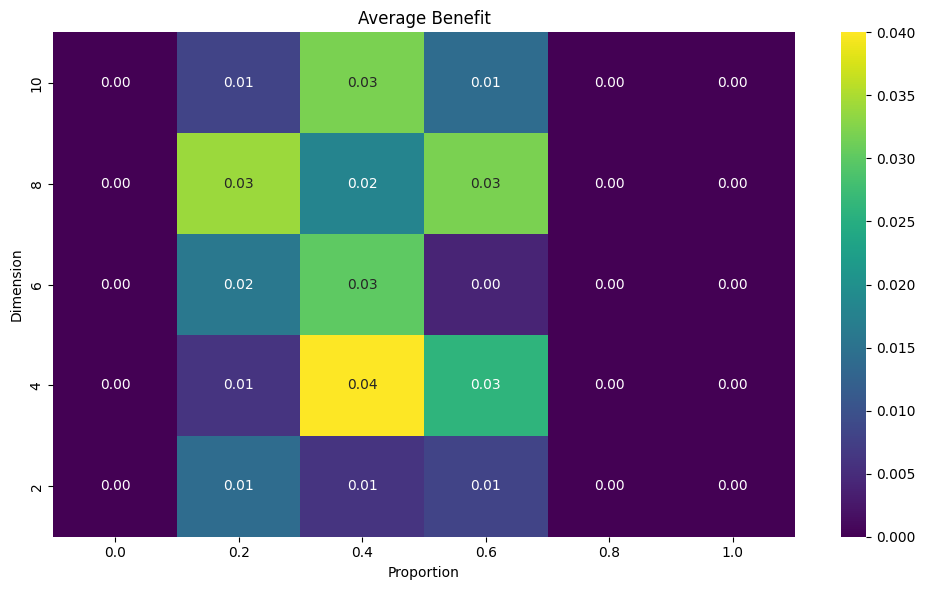

In [62]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

dimension_indices = {dim: i for i, dim in enumerate(d_list)}
proportion_indices = {prop: j for j, prop in enumerate(p_list)}

import numpy as np

benefit_sums = np.zeros((len(d_list), len(p_list)))
benefit_counts = np.zeros((len(d_list), len(p_list)))

for entry in data_reverse_euclidean_gain:
    dim = entry[0]
    prop = entry[1]
    benefit_list = entry[7]

    i = dimension_indices[dim]
    j = proportion_indices[prop]

    benefit_sums[i, j] += sum(benefit_list)
    benefit_counts[i, j] += len(benefit_list)

average_benefits = benefit_sums / benefit_counts

df = pd.DataFrame(average_benefits, index=d_list, columns=p_list)

plt.figure(figsize=(10, 6))
sns.heatmap(df, annot=True, fmt=".2f", cmap='viridis')
plt.title("Average Benefit")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Expectations Euclidean**

In [63]:
import numpy as np

def convert_to_builtin(obj):
    if isinstance(obj, dict):
        return {convert_to_builtin(k): convert_to_builtin(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_builtin(elem) for elem in obj]
    elif isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.floating):
        return float(obj)
    else:
        return obj
    
import numpy as np

def generate_expectation_votes(num_agents: int = None,
                               dim: int = None,
                               space='uniform',
                               std: float = None,
                               phi=0.5,
                               **kwargs):
    name = f'{dim}d_{space}'

    left_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    left_agents_wishes = np.zeros([num_agents, dim])

    right_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    right_agents_wishes = np.zeros([num_agents, dim])

    for v in range(num_agents):
        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        left_agents_wishes[v][0] = np.random.normal(left_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        left_agents_wishes[v][1] = np.random.normal(left_agents_reality[v][1], std)

        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        right_agents_wishes[v][0] = np.random.normal(right_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        right_agents_wishes[v][1] = np.random.normal(right_agents_reality[v][1], std)

    left_votes = np.zeros([num_agents, num_agents], dtype=int)
    right_votes = np.zeros([num_agents, num_agents], dtype=int)
    distances = np.zeros([num_agents, num_agents], dtype=float)

    for v in range(num_agents):
        for c in range(num_agents):
            left_votes[v][c] = c
            distances[v][c] = np.linalg.norm(right_agents_reality[c] - left_agents_wishes[v])
        left_votes[v] = [x for _, x in sorted(zip(distances[v], left_votes[v]))]

    for v in range(num_agents):
        for c in range(num_agents):
            right_votes[v][c] = c
            distances[v][c] = np.linalg.norm(left_agents_reality[c] - right_agents_wishes[v])
        right_votes[v] = [x for _, x in sorted(zip(distances[v], right_votes[v]))]

    left_votes_lst = [list(row) for row in left_votes]
    right_votes_lst = [list(row) for row in right_votes]


    for i in range(len(left_votes_lst)):
        for j in range(len(left_votes_lst[i])):
            left_votes_lst[i][j] = left_votes_lst[i][j] + 1
    for i in range(len(right_votes_lst)):
        for j in range(len(right_votes_lst[i])):
            right_votes_lst[i][j] = right_votes_lst[i][j] + 1

    return [left_votes_lst, right_votes_lst]

In [64]:
data_expectations_euclidean_gain = []

n=5
std_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]

for d in tqdm(d_list):
    number_phi = []
    for std in tqdm(std_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref=generate_expectation_votes(n, d, 'uniform', std, 0.5)
            mpref=pref[0]
            wpref=pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_expectations_euclidean_gain.append([d, std, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)




100%|██████████| 5/5 [00:01<00:00,  4.21it/s]


In [65]:
df6 = pd.DataFrame(data_expectations_euclidean_gain, columns=["dimension", "std", "mpref", "preferences", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df6.to_csv('expectations_euclidean_gain.csv', index=False)

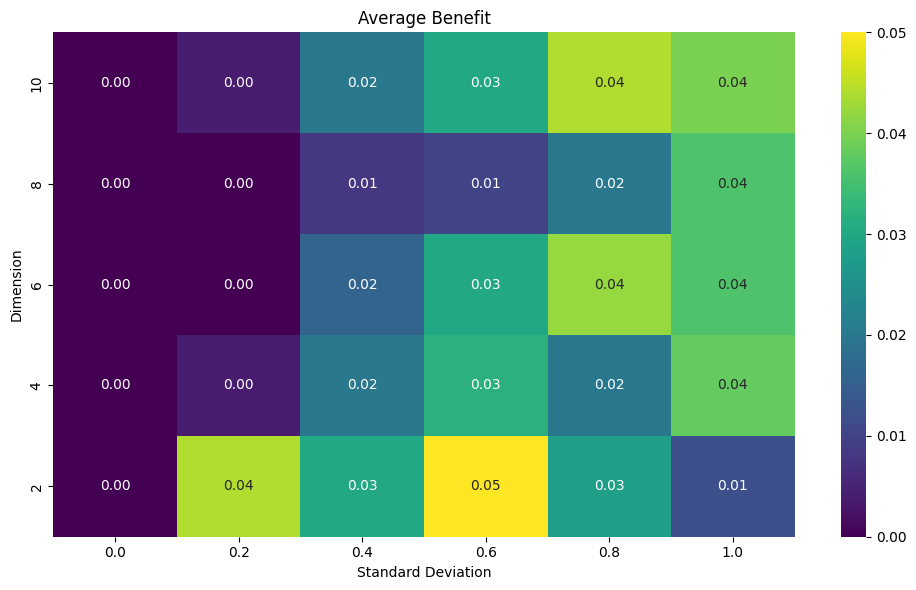

In [66]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

dimension_indices = {dim: i for i, dim in enumerate(d_list)}
std_indices = {std: j for j, std in enumerate(std_list)}

import numpy as np

benefit_sums = np.zeros((len(d_list), len(std_list)))
benefit_counts = np.zeros((len(d_list), len(std_list)))

for entry in data_expectations_euclidean_gain:
    dim = entry[0]
    std = entry[1]
    benefit_list = entry[7]

    i = dimension_indices[dim]
    j = std_indices[std]

    benefit_sums[i, j] += sum(benefit_list)
    benefit_counts[i, j] += len(benefit_list)

average_benefits = benefit_sums / benefit_counts

df = pd.DataFrame(average_benefits, index=d_list, columns=std_list)

plt.figure(figsize=(10, 6))
sns.heatmap(df, annot=True, fmt=".2f", cmap='viridis')
plt.title("Average Benefit")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



**Fame Euclidean**

In [67]:
data_fame_euclidean_gain = []

n=5
f_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 3, 5, 10]

for d in tqdm(d_list):
    number_phi = []
    for f in tqdm(f_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref = generate_fame_votes(n, d, 'uniform', f)
            mpref=pref[0]
            wpref=pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_fame_euclidean_gain.append([d, f, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)




100%|██████████| 4/4 [00:00<00:00,  6.10it/s]


In [68]:
df7 = pd.DataFrame(data_fame_euclidean_gain, columns=["dimension", "fame", "preferences", "sample", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df7.to_csv('fame_euclidean_gain.csv', index=False)

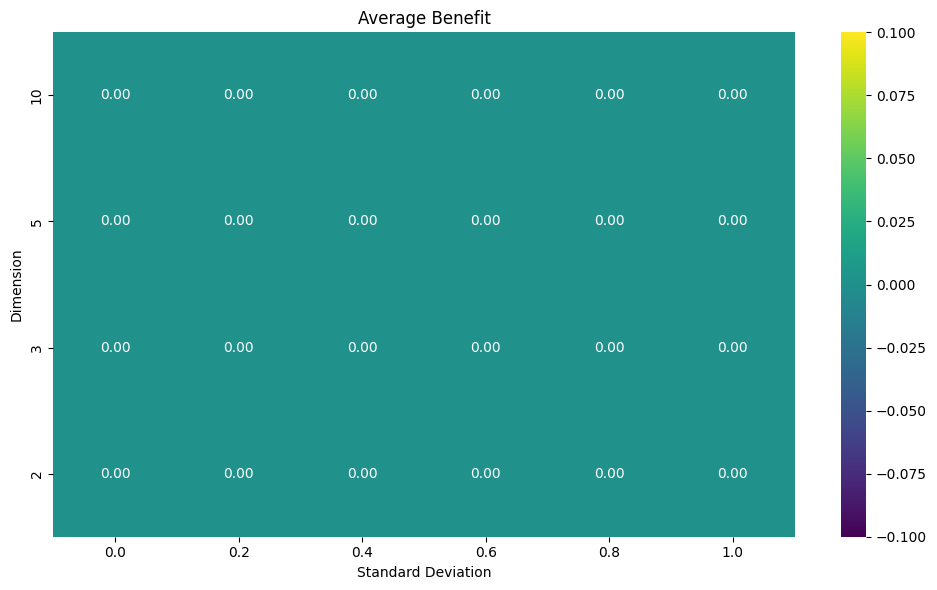

In [69]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

dimension_indices = {dim: i for i, dim in enumerate(d_list)}
fame_indices = {fame: j for j, fame in enumerate(f_list)}

import numpy as np

benefit_sums = np.zeros((len(d_list), len(f_list)))
benefit_counts = np.zeros((len(d_list), len(f_list)))

for entry in data_fame_euclidean_gain:
    dim = entry[0]
    fame = entry[1]
    benefit_list = entry[7]

    i = dimension_indices[dim]
    j = fame_indices[fame]

    benefit_sums[i, j] += sum(benefit_list)
    benefit_counts[i, j] += len(benefit_list)

average_benefits = benefit_sums / benefit_counts

df = pd.DataFrame(average_benefits, index=d_list, columns=f_list)

plt.figure(figsize=(10, 6))
sns.heatmap(df, annot=True, fmt=".2f", cmap='viridis')
plt.title("Average Benefit")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()




In [85]:
def gale_shapley(mpref, wpref, strategic_woman=0):
    n = len(mpref)
    curr_match_count = 0
    last_rejected_by_rank_what = [0 for i in range(n)]
    men_matchings = [0 for i in range(n)]
    women_matchings = [0 for i in range(n)]
    proposals_to_strategic_woman = set()    # Only used if strategic_woman != 0

    # continue until all matches made
    while curr_match_count < n:
        for man in range(n):
            # if man is single
            if men_matchings[man] == 0:
                # get first non-rejecting woman from man's preference list
                woman = mpref[man][last_rejected_by_rank_what[man]] - 1
                if woman + 1 == strategic_woman:
                    proposals_to_strategic_woman.add(man + 1)

                # both man and woman are single
                if women_matchings[woman] == 0:
                    # create match (man, woman)
                    men_matchings[man] = woman + 1
                    women_matchings[woman] = man + 1
                    curr_match_count += 1

                # woman is with someone
                else:
                    # find ranks of curr_partner and man given woman's preference list
                    curr_partner = women_matchings[woman]
                    curr_partner_rank = wpref[woman].index(curr_partner)
                    man_rank = wpref[woman].index(man + 1)

                    # woman prefers curr_partner over man
                    if curr_partner_rank < man_rank:
                        last_rejected_by_rank_what[man] = mpref[man].index(woman + 1) + 1

                    # woman prefers man over curr_partner
                    else:
                        men_matchings[curr_partner - 1] = 0
                        last_rejected_by_rank_what[curr_partner - 1] = mpref[curr_partner - 1].index(woman + 1) + 1
                        men_matchings[man] = woman + 1
                        women_matchings[woman] = man + 1

    if strategic_woman != 0:
        return men_matchings, proposals_to_strategic_woman
    else:
        return men_matchings


def get_m_partner(m, matches):
    return matches[m - 1]


def get_w_partner(w, matches):
    return matches.index(w) + 1


def get_m_rank(m, mpref, matches):
    partner = matches[m - 1]
    return mpref[m - 1].index(partner) + 1


def get_w_rank(w, wpref, matches):
    partner = matches.index(w) + 1
    return wpref[w - 1].index(partner) + 1

In [86]:
#from ApproximateSP import *


def accomplice_manipulation(mpref, wpref, manipulator, accomplice, with_regret=False):
    n = len(mpref)

    if accomplice == -1:
        return test_all_accomplices(mpref, wpref, manipulator, n)

    gs_matches = gale_shapley(mpref, wpref)
    manipulated_matches = gs_matches[:]
    manipulated_list = mpref[accomplice - 1][:]
    mpref_new = mpref[:]

    rank_of_gs_partner_of_manipulator = get_w_rank(manipulator, wpref, gs_matches)
    rank_of_gs_partner_of_accomplice = get_m_rank(accomplice, mpref, gs_matches)

    best_rank_of_partner = n + 1
    for i in range(rank_of_gs_partner_of_accomplice, n):
        temp = mpref[accomplice - 1][:]
        woman = temp[i]

        if with_regret or wpref[woman - 1].index(accomplice) < get_w_rank(woman, wpref, gs_matches):
            temp.remove(woman)
            temp.insert(0, woman)
            mpref_new[accomplice - 1] = temp
            matches_new = gale_shapley(mpref_new, wpref)

            rank_of_manipulated_partner_of_accomplice = get_m_rank(accomplice, mpref, matches_new)
            if with_regret or rank_of_manipulated_partner_of_accomplice == rank_of_gs_partner_of_accomplice:
                rank_of_manipulated_partner_of_manipulator = get_w_rank(manipulator, wpref, matches_new)
                if rank_of_manipulated_partner_of_manipulator < best_rank_of_partner:
                    best_rank_of_partner = rank_of_manipulated_partner_of_manipulator
                    if rank_of_manipulated_partner_of_manipulator < rank_of_gs_partner_of_manipulator:
                        manipulated_list = temp[:]
                        manipulated_matches = matches_new[:]

    return manipulated_matches, manipulated_list


def test_all_accomplices(mpref, wpref, manipulator, n):
    best_rank_of_partner = n + 1
    best_accomplice = 0
    best_matches = 0
    best_list = []
    for accomplice in range(1, n + 1):
        results = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
        rank_of_partner = get_w_rank(manipulator, wpref, results[0])
        if rank_of_partner < best_rank_of_partner:
            best_rank_of_partner = rank_of_partner
            best_accomplice = accomplice
            best_matches = results[0]
            best_list = results[1]

    return best_matches, best_list, best_accomplice










n=5: 100%|██████████| 1/1 [00:00<00:00,  1.22it/s]








n=10: 100%|██████████| 1/1 [00:01<00:00,  1.43s/it]








n=15: 100%|██████████| 1/1 [00:05<00:00,  5.64s/it]








n=20: 100%|██████████| 1/1 [00:19<00:00, 19.55s/it]








n=25: 100%|██████████| 1/1 [00:51<00:00, 51.69s/it]








n=30: 100%|██████████| 1/1 [01:59<00:00, 119.92s/it]


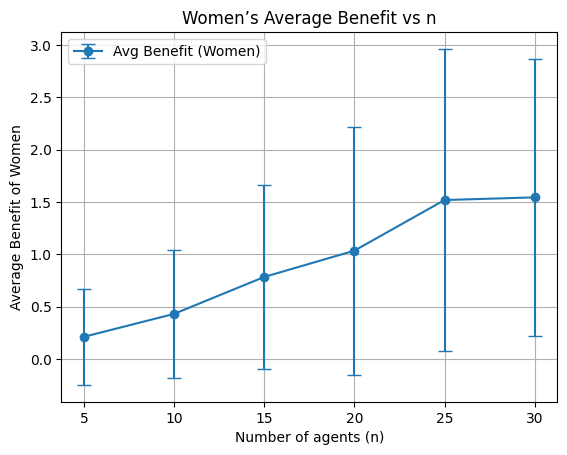

In [88]:
#Code for varying n



import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

data_mallows_gain = []

phi_list = [1.0]
n_list = [5, 10, 15, 20, 25, 30]

# store aggregated statistics
results_summary = []

for n in n_list:
    for phi1 in tqdm(phi_list, desc=f"n={n}"):
        for phi2 in tqdm(phi_list, leave=False):
            
            sample_avgs = []  # store avg benefit_women per sample

            for samples in range(100):
                # generate Mallows preferences
                m_pref = [generate_ic_votes(n)[0]] * n
                w_pref = [generate_ic_votes(n)[0]] * n
                mpref = mallows_votes(m_pref, phi1)
                wpref = mallows_votes(w_pref, phi2)

                benefit_women = []

                for manipulator in range(1, n+1):
                    # original matching
                    matching = gale_shapley(mpref, wpref)
                    result = test_all_accomplices(mpref, wpref, manipulator, n)
                    matching2 = result[0]

                    # find partners before and after manipulation
                    partner1, partner2 = None, None
                    for i in range(n):
                        if matching[i] == manipulator:
                            partner1 = i+1
                        if matching2[i] == manipulator:
                            partner2 = i+1

                    # rank positions in woman's preference
                    w_pref_m = wpref[manipulator-1]
                    rk1 = w_pref_m.index(partner1)
                    rk2 = w_pref_m.index(partner2)

                    # benefit = improvement in rank (positive = better for woman)
                    benefit = rk1 - rk2
                    benefit_women.append(benefit)

                # average benefit for this sample
                avg_benefit_women = np.mean(benefit_women)
                sample_avgs.append(avg_benefit_women)

                data_mallows_gain.append([
                    phi1, phi2, n, samples,
                    avg_benefit_women, benefit_women
                ])

            # aggregate across 100 samples
            mean_benefit = np.mean(sample_avgs)
            std_benefit = np.std(sample_avgs)

            results_summary.append([phi1, phi2, n, mean_benefit, std_benefit])

# ---- Convert results into numpy arrays for plotting ----
results_summary = np.array(results_summary, dtype=object)

# Extract plotting data
n_vals = results_summary[:, 2].astype(int)
means = results_summary[:, 3].astype(float)
stds = results_summary[:, 4].astype(float)

# ---- Plot ----
plt.errorbar(n_vals, means, yerr=stds, fmt='o-', capsize=5, label="Avg Benefit (Women)")
plt.xlabel("Number of agents (n)")
plt.ylabel("Average Benefit of Women")
plt.title("Women’s Average Benefit vs n")
plt.legend()
plt.grid(True)
plt.show()
